In [1]:
!pip -q install elevation rasterio shapely geopandas

In [2]:
import os
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

from pathlib import Path

In [3]:
DATA_DIR = Path("N:\\Projects\\Wind_Energy_ML\\data")
SRTM_DIR = DATA_DIR / "srtm"
TERRAIN_DIR = DATA_DIR / "terrain"

SRTM_DIR.mkdir(parents=True, exist_ok=True)
TERRAIN_DIR.mkdir(parents=True, exist_ok=True)

print("SRTM directory:", SRTM_DIR)
print("Terrain directory:", TERRAIN_DIR)

SRTM directory: N:\Projects\Wind_Energy_ML\data\srtm
Terrain directory: N:\Projects\Wind_Energy_ML\data\terrain


In [4]:
test_lat = 22.3039
test_lon = 70.8022

print("Latitude:", test_lat)
print("Longitude:", test_lon)

Latitude: 22.3039
Longitude: 70.8022


In [1]:
import elevation
import sys
import shutil

print("Python:", sys.version)
print("Elevation package:", elevation.__file__)
print("Make executable:", shutil.which("make"))
print("Cache directory:", elevation.datasource.CACHE_DIR
      if hasattr(elevation, "datasource") else "Check package configuration")

Python: 3.14.7 (main, Sep  1 2026, 14:17:30) [MSC v.1944 64 bit (AMD64)]
Elevation package: n:\Projects\Wind_Energy_ML\.venv\Lib\site-packages\elevation\__init__.py
Make executable: None
Cache directory: C:\Users\nalla\AppData\Local\bopen\elevation\Cache


In [4]:
python -m pip show elevation
python -m pip show GDAL
where.exe make
where.exe curl
where.exe gdalinfo

SyntaxError: invalid syntax (1998386999.py, line 1)

In [11]:
import elevation

test_dem = SRTM_DIR / "test_dem_inland.tif"

elevation.clip(
    bounds=(
        test_lon - 0.05,
        test_lat - 0.05,
        test_lon + 0.05,
        test_lat + 0.05
    ),
    output=str(test_dem)
)

print("DEM created:", test_dem.exists())
print("File:", test_dem)

CalledProcessError: Command 'make -C C:\Users\nalla\AppData\Local\bopen\elevation\Cache\SRTM1 download ENSURE_TILES="N22/N22E070.tif"' returned non-zero exit status 1.

In [12]:
import numpy as np
import rasterio

with rasterio.open(test_dem) as src:
    dem = src.read(1, masked=True)

    transform = src.transform
    crs = src.crs
    nodata = src.nodata
    bounds = src.bounds
    resolution = src.res

valid_elevation = dem.compressed()

print("CRS:", crs)
print("Resolution:", resolution)
print("Shape:", dem.shape)
print("NoData value:", nodata)
print("Masked pixels:", np.ma.getmaskarray(dem).sum())

if valid_elevation.size > 0:
    print("Minimum elevation:", valid_elevation.min())
    print("Maximum elevation:", valid_elevation.max())
    print("Mean elevation:", valid_elevation.mean())
else:
    print("No valid elevation pixels found.")

RasterioIOError: N:\Projects\Wind_Energy_ML\data\srtm\test_dem_inland.tif: No such file or directory

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.imshow(
    dem,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    origin="upper",
    cmap="terrain"
)

plt.colorbar(label="Elevation (m)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("SRTM Elevation — Inland Test Area")

plt.show()

NameError: name 'dem' is not defined

<Figure size 1000x800 with 0 Axes>

In [9]:
from rasterio.transform import xy

pixel_x = abs(transform.a)
pixel_y = abs(transform.e)

print("Longitude pixel size:", pixel_x)
print("Latitude pixel size :", pixel_y)

Longitude pixel size: 0.0002777777777777778
Latitude pixel size : 0.0002777777777777778


In [10]:

# ============================================
# STEP 2.2 — CALCULATE TERRAIN SLOPE
# ============================================

# Convert the masked elevation raster to float
dem_values = dem.astype("float64").filled(np.nan)

# Latitude of each raster row (pixel centers)
row_indices = np.arange(dem.shape[0])

row_latitudes = (
    transform.f
    + (row_indices + 0.5) * transform.e
)

# Approximate pixel dimensions in metres
pixel_height_m = 110574 * abs(transform.e)

pixel_width_m = (
    111320
    * np.cos(np.deg2rad(row_latitudes))
    * abs(transform.a)
)

# Elevation gradients per pixel
dz_drow = np.gradient(dem_values, axis=0)
dz_dcol = np.gradient(dem_values, axis=1)

# Convert gradients to elevation change per metre
dz_dy = dz_drow / pixel_height_m
dz_dx = dz_dcol / pixel_width_m[:, None]

# Calculate slope in degrees
slope_deg = np.degrees(
    np.arctan(np.hypot(dz_dx, dz_dy))
)

# Mask cells where elevation is invalid
invalid = (
    np.ma.getmaskarray(dem)
    | ~np.isfinite(dem_values)
)

slope_deg[invalid] = np.nan

print("Slope calculation completed.")
print("Minimum slope:", np.nanmin(slope_deg))
print("Maximum slope:", np.nanmax(slope_deg))
print("Mean slope:", np.nanmean(slope_deg))


Slope calculation completed.
Minimum slope: 0.0
Maximum slope: 32.50637002971131
Mean slope: 2.664212163006877


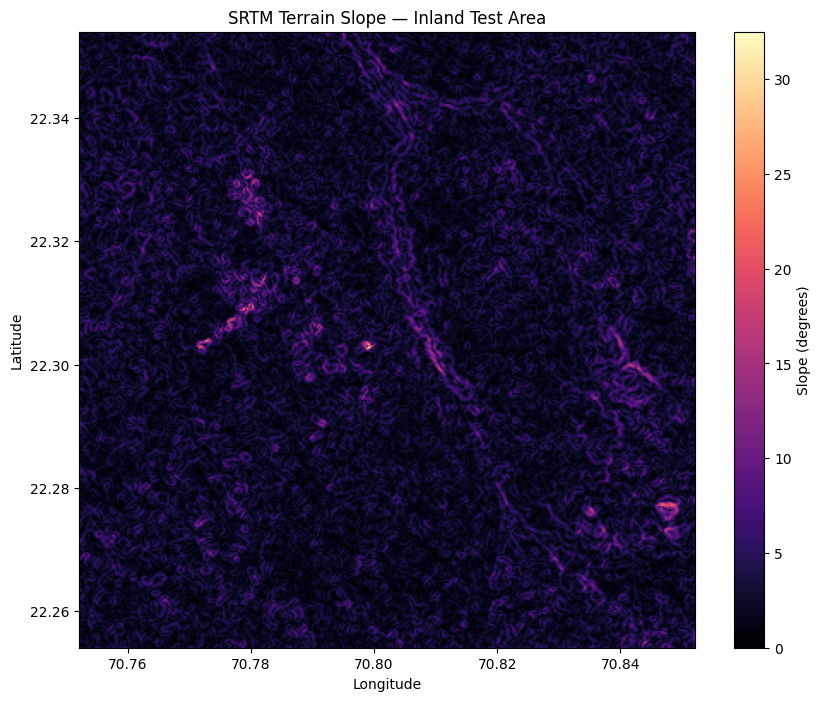

In [11]:

plt.figure(figsize=(10, 8))

plt.imshow(
    slope_deg,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    origin="upper",
    cmap="magma",
    vmin=0
)

plt.colorbar(label="Slope (degrees)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("SRTM Terrain Slope — Inland Test Area")

plt.show()


In [12]:

from scipy.ndimage import uniform_filter

# ============================================
# STEP 2.3 — TERRAIN VARIABILITY
# ============================================

# Use a neighbourhood approximately 500 m wide
window_size = 17
half_window = window_size // 2

# Identify valid elevation pixels
valid_mask = np.isfinite(dem_values)

# Replace invalid cells temporarily for calculation
safe_dem = np.where(valid_mask, dem_values, 0.0)
valid_float = valid_mask.astype(float)

# Local proportion of valid pixels
valid_fraction = uniform_filter(
    valid_float,
    size=window_size,
    mode="constant",
    cval=0.0
)

# Avoid division by zero
valid_fraction = np.maximum(valid_fraction, 1e-12)

# Local mean elevation
local_mean = (
    uniform_filter(
        safe_dem,
        size=window_size,
        mode="constant",
        cval=0.0
    ) / valid_fraction
)

# Local mean squared elevation
local_mean_sq = (
    uniform_filter(
        safe_dem ** 2,
        size=window_size,
        mode="constant",
        cval=0.0
    ) / valid_fraction
)

# Local elevation variance and standard deviation
local_variance = np.maximum(
    local_mean_sq - local_mean ** 2,
    0.0
)

elevation_std_500m = np.sqrt(local_variance)

# Exclude invalid cells
elevation_std_500m[~valid_mask] = np.nan

# Exclude the raster edges where the full neighbourhood
# is not available
elevation_std_500m[:half_window, :] = np.nan
elevation_std_500m[-half_window:, :] = np.nan
elevation_std_500m[:, :half_window] = np.nan
elevation_std_500m[:, -half_window:] = np.nan

print("Terrain variability calculated.")
print("Minimum:", np.nanmin(elevation_std_500m), "m")
print("Maximum:", np.nanmax(elevation_std_500m), "m")
print("Mean:", np.nanmean(elevation_std_500m), "m")


Terrain variability calculated.
Minimum: 1.0485399706356462 m
Maximum: 10.228037743054152 m
Mean: 2.57237357483133 m


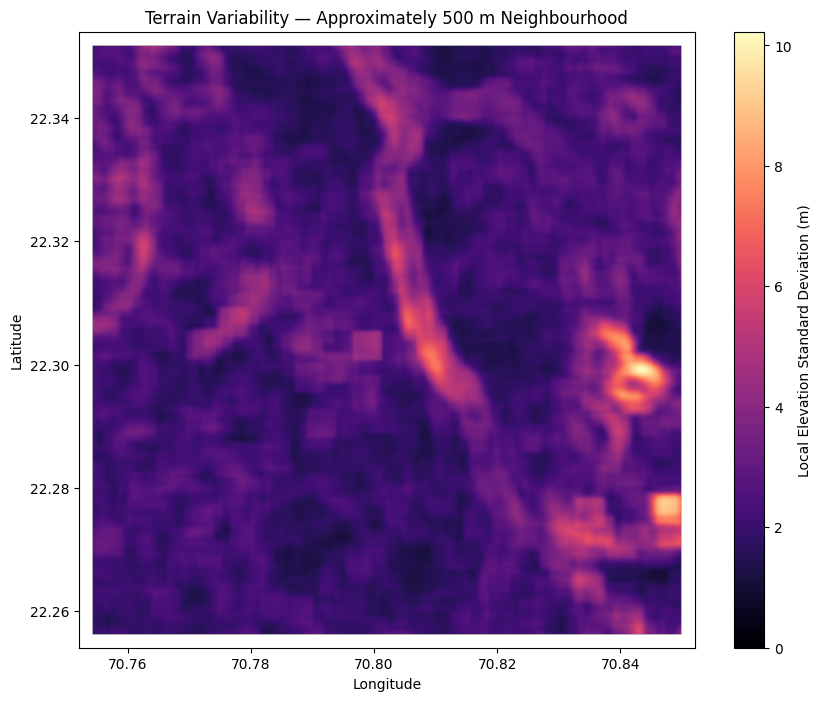

In [13]:

plt.figure(figsize=(10, 8))

plt.imshow(
    elevation_std_500m,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    origin="upper",
    cmap="magma",
    vmin=0
)

plt.colorbar(
    label="Local Elevation Standard Deviation (m)"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Terrain Variability — Approximately 500 m Neighbourhood")

plt.show()


In [14]:

# ============================================
# STEP 2.4 — LOAD NIWE POINTS IN THE TEST AREA
# ============================================

from pathlib import Path
import pandas as pd
import rasterio

NIWE_FILE = Path("data/raw/150m_Map_Data_A_to_G.csv")
CHUNK_SIZE = 100_000

rename_map = {
    "Longitude (E)": "longitude",
    "Latitude (N)": "latitude",
    "Wind Speed (m/s)": "wind_speed",
    "Weibull A (m/s)": "weibull_a",
    "Weibull k": "weibull_k",
    "Air Density (kg/m3)": "air_density",
    "Wind Power Density (W/sq.m)": "wind_power_density"
}

if not NIWE_FILE.exists():
    raise FileNotFoundError(
        f"NIWE CSV not found: {NIWE_FILE}. "
        "Update NIWE_FILE to your actual file location."
    )

# Read bounds from the test DEM
with rasterio.open(test_dem) as src:
    bounds = src.bounds

print("DEM bounds:", bounds)

# Read the NIWE file in chunks and retain only
# the points inside the test DEM area.
local_parts = []

for chunk in pd.read_csv(
    NIWE_FILE,
    usecols=list(rename_map.keys()),
    chunksize=CHUNK_SIZE
):
    chunk = chunk.rename(columns=rename_map)

    inside = (
        chunk["longitude"].between(
            bounds.left, bounds.right
        )
        & chunk["latitude"].between(
            bounds.bottom, bounds.top
        )
    )

    if inside.any():
        local_parts.append(
            chunk.loc[inside].copy()
        )

if local_parts:
    niwe_local = pd.concat(
        local_parts,
        ignore_index=True
    )
else:
    niwe_local = pd.DataFrame(
        columns=list(rename_map.values())
    )

print("NIWE points inside test DEM:", len(niwe_local))
display(niwe_local.head())


DEM bounds: BoundingBox(left=70.75208333333333, bottom=22.254027777777775, right=70.85208333333333, top=22.354027777777777)
NIWE points inside test DEM: 625


,longitude,latitude,wind_speed,weibull_a,weibull_k,air_density,wind_power_density
0,70.754,22.258,6.561,7.374,2.739,1.138,238.23
1,70.754,22.262,6.546,7.358,2.735,1.139,237.03
2,70.754,22.266,6.533,7.343,2.734,1.139,235.68
3,70.754,22.270,6.524,7.333,2.734,1.139,234.69
4,70.754,22.274,6.521,7.330,2.735,1.139,234.32


In [15]:

# ============================================
# STEP 2.5 — CREATE APPROX. 500 m AGGREGATES
# ============================================

from scipy.ndimage import uniform_filter

window_size = 17
half_window = window_size // 2


def neighbourhood_mean(array, window=17):
    """Calculate a local mean; require a complete valid window."""

    valid = np.isfinite(array)
    safe = np.where(valid, array, 0.0)

    local_sum = uniform_filter(
        safe,
        size=window,
        mode="constant",
        cval=0.0
    )

    valid_fraction = uniform_filter(
        valid.astype(float),
        size=window,
        mode="constant",
        cval=0.0
    )

    result = local_sum / np.maximum(valid_fraction, 1e-12)

    # Require all pixels in the neighbourhood to be valid.
    result[valid_fraction < 0.999999] = np.nan

    # Exclude edges where a complete neighbourhood is unavailable.
    h = window // 2
    result[:h, :] = np.nan
    result[-h:, :] = np.nan
    result[:, :h] = np.nan
    result[:, -h:] = np.nan

    return result


# Average elevation across the neighbourhood
elevation_mean_500m = neighbourhood_mean(
    dem_values,
    window_size
)

# Average slope across the same neighbourhood
slope_mean_500m = neighbourhood_mean(
    slope_deg,
    window_size
)

print("Elevation aggregate calculated.")
print("Slope aggregate calculated.")
print("Elevation variability raster already available.")


Elevation aggregate calculated.
Slope aggregate calculated.
Elevation variability raster already available.


In [16]:

# ============================================
# STEP 2.6 — EXTRACT TERRAIN AT NIWE LOCATIONS
# ============================================

from rasterio.transform import rowcol

# Convert geographic coordinates to raster indices
rows, cols = rowcol(
    transform,
    niwe_local["longitude"].to_numpy(),
    niwe_local["latitude"].to_numpy()
)

rows = np.asarray(rows)
cols = np.asarray(cols)

# Keep only points with enough raster area around them
# to calculate a complete 17 x 17 neighbourhood.
inside_full_window = (
    (rows >= half_window)
    & (rows < dem_values.shape[0] - half_window)
    & (cols >= half_window)
    & (cols < dem_values.shape[1] - half_window)
)

terrain_test = niwe_local.loc[
    inside_full_window
].copy()

valid_rows = rows[inside_full_window]
valid_cols = cols[inside_full_window]

# Add local terrain features
terrain_test["elevation_m"] = elevation_mean_500m[
    valid_rows, valid_cols
]

terrain_test["slope_deg"] = slope_mean_500m[
    valid_rows, valid_cols
]

terrain_test["elevation_std_500m"] = elevation_std_500m[
    valid_rows, valid_cols
]

print("Original NIWE points:", len(niwe_local))
print("Points with full terrain neighbourhood:", len(terrain_test))
print(
    "Rows with missing terrain values:",
    terrain_test[
        ["elevation_m", "slope_deg", "elevation_std_500m"]
    ].isna().any(axis=1).sum()
)

display(terrain_test.head())


Original NIWE points: 625
Points with full terrain neighbourhood: 552
Rows with missing terrain values: 0


,longitude,latitude,wind_speed,weibull_a,weibull_k,air_density,wind_power_density,elevation_m,slope_deg,elevation_std_500m
25,70.758,22.258,6.560,7.373,2.743,1.138,237.89,138.619377,2.181789,1.713100
26,70.758,22.262,6.548,7.359,2.739,1.139,237.02,135.934256,1.886642,1.964874
27,70.758,22.266,6.537,7.347,2.738,1.139,235.89,132.148789,2.625817,1.895726
28,70.758,22.270,6.531,7.340,2.739,1.139,235.18,129.584775,3.119011,2.833422
29,70.758,22.274,6.531,7.340,2.740,1.139,235.12,130.093426,2.992127,2.538614


In [17]:

terrain_columns = [
    "elevation_m",
    "slope_deg",
    "elevation_std_500m"
]

print("Test dataset shape:", terrain_test.shape)

display(
    terrain_test[terrain_columns].describe().T
)

print("\nMissing values:")
print(terrain_test[terrain_columns].isna().sum())

print("\nNegative slope values:")
print((terrain_test["slope_deg"] < 0).sum())

print("\nNegative terrain variability values:")
print((terrain_test["elevation_std_500m"] < 0).sum())


Test dataset shape: (552, 10)


,count,mean,std,min,25%,50%,75%,max
elevation_m,552.0,132.407897,10.169605,104.567474,124.493945,133.200692,140.365917,153.982699
slope_deg,552.0,2.659679,0.647517,1.522679,2.206971,2.557450,2.915040,5.539353
elevation_std_500m,552.0,2.554955,1.014638,1.095340,1.924123,2.290494,2.874096,8.396613



Missing values:
elevation_m           0
slope_deg             0
elevation_std_500m    0
dtype: int64

Negative slope values:
0

Negative terrain variability values:
0


In [18]:

# ============================================
# STEP 2.7 — SAVE TERRAIN INTEGRATION TEST
# ============================================

from pathlib import Path

TERRAIN_DIR = Path("data/terrain")
TERRAIN_DIR.mkdir(parents=True, exist_ok=True)

test_output = (
    TERRAIN_DIR / "niwe_srtm_terrain_test_rajkot.csv"
)

terrain_test.to_csv(test_output, index=False)

print("Test dataset saved successfully.")
print("Output path:", test_output)
print("Rows:", len(terrain_test))
print("Columns:", len(terrain_test.columns))

display(terrain_test.head())


Test dataset saved successfully.
Output path: data/terrain/niwe_srtm_terrain_test_rajkot.csv
Rows: 552
Columns: 10


,longitude,latitude,wind_speed,weibull_a,weibull_k,air_density,wind_power_density,elevation_m,slope_deg,elevation_std_500m
25,70.758,22.258,6.560,7.373,2.743,1.138,237.89,138.619377,2.181789,1.713100
26,70.758,22.262,6.548,7.359,2.739,1.139,237.02,135.934256,1.886642,1.964874
27,70.758,22.266,6.537,7.347,2.738,1.139,235.89,132.148789,2.625817,1.895726
28,70.758,22.270,6.531,7.340,2.739,1.139,235.18,129.584775,3.119011,2.833422
29,70.758,22.274,6.531,7.340,2.740,1.139,235.12,130.093426,2.992127,2.538614
